# Incident Copilot — разведочный анализ данных

**DL-трек · NLP · Чекпойнт №2**

В этом ноутбуке мы исследуем четыре типа данных для Incident Copilot: контексты технических вопросов, документацию ПО, runbooks и отчёты об инцидентах. Наша задача — понять, что содержится в каждом источнике, где возникают проблемы с качеством и как эти данные использовать в будущей RAG-системе.

Мы проанализировали **658 документов и 910 QA-пар**. Все основные таблицы и графики рассчитываются в ноутбуке. Загрузка и первичная подготовка данных вынесены в `src/eda/`.

**Разделы:** источники данных → качество и QA-разметка → структура документов → сравнение лексики → эмбеддинги → поисковые кандидаты → аугментации → выводы.

## 1. Задача и исследовательские гипотезы

Мы проверяем четыре предположения:

1. **Структура документов.** Документация, runbooks и отчёты об инцидентах различаются по объёму и устройству. Возможно, для них понадобятся разные способы разбиения на чанки.
2. **Технические идентификаторы.** Коды ошибок, команды и версии ПО помогают найти точный документ. Нужно оценить, достаточно ли одного семантического поиска или стоит добавить BM25.
3. **Разные источники знаний.** Вопросы пользователей, инструкции и постмортемы описывают проблемы разным языком. Проверим, насколько они пересекаются по лексике и эмбеддингам.
4. **Устойчивость к формулировкам.** Перефразирования и опечатки меняют представление запроса. Посмотрим, насколько сильно и не теряются ли технические идентификаторы.

Для части признаков используем результаты предварительной обработки (`reports/document_features.csv` и матрицу эмбеддингов). Остальные статистики и графики пересчитываем из подготовленных данных здесь.

In [44]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
rng = np.random.default_rng(SEED)
ROOT = Path.cwd()
if not (ROOT / 'data/processed/documents.json').exists():
    raise FileNotFoundError('Нет data/processed/documents.json. Подготовьте корпус по инструкции data/README.md и запустите ноутбук из корня репозитория.')
plt.rcParams.update({'figure.figsize': (9, 4.7), 'axes.titlesize': 12, 'font.size': 10, 'figure.dpi': 110})
COLORS = {'qa_context': '#4967ad', 'documentation': '#009688', 'runbook': '#d28d30', 'incident': '#b55779'}
ORDER = ['qa_context','documentation','runbook','incident']
print('Данные:', Path('data/processed'))
print('Случайное зерно:', SEED)

Данные: data\processed
Случайное зерно: 42


### 1.1. Откуда взялись данные

В исследовании четыре источника: TechQA, документация Kubernetes, runbooks GitLab и публичные отчёты об инцидентах. TechQA посвящён продуктам IBM, поэтому используем его как отдельный QA-датасет. Остальные три источника изучаем как основу будущей базы знаний для SRE.

В выборке пока 10 постмортемов. Этого достаточно, чтобы начать анализ структуры отчётов; расширение корпуса оставляем на следующий этап.

Данные хранятся в трёх таблицах: `documents` — тексты источников, `qa` — вопросы и ответы, `document_features` — рассчитанные признаки. QA-пары не дублируем в таблице документов.

In [45]:
documents = pd.DataFrame(json.loads((ROOT/'data/processed/documents.json').read_text(encoding='utf-8')))
qa = pd.DataFrame(json.loads((ROOT/'data/processed/qa.json').read_text(encoding='utf-8')))
features = pd.read_csv(ROOT/'reports/document_features.csv')
docs = documents.merge(features.drop(columns=['source_type','language'], errors='ignore'), on='document_id', how='left', validate='one_to_one')
assert docs.document_id.is_unique
assert qa.query_id.is_unique
assert set(qa.context_ids.explode().dropna()).issubset(set(docs.document_id))
assert len(docs)==len(documents)==len(features)
print(f'Документов: {len(docs):,}; QA-пар: {len(qa):,}')
display(pd.DataFrame({'таблица':['documents','qa','document_features'], 'записи':[len(documents),len(qa),len(features)], 'поля':[len(documents.columns),len(qa.columns),len(features.columns)]}))

Документов: 658; QA-пар: 910


,таблица,записи,поля
0,documents,658,13
1,qa,910,7
2,document_features,658,26


,Тип источника,Документов
0,qa_context,496
1,documentation,95
2,runbook,57
3,incident,10


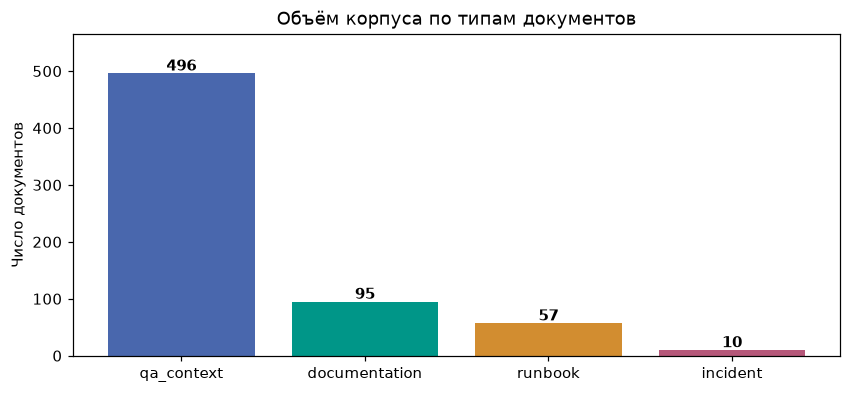

In [46]:
# Доли источников рассчитываем непосредственно из документов
source_counts = docs.source_type.value_counts().reindex(ORDER, fill_value=0)
display(source_counts.rename_axis('Тип источника').reset_index(name='Документов'))
fig, ax = plt.subplots(figsize=(9,3.8))
ax.bar(source_counts.index,source_counts.values,color=[COLORS[s] for s in source_counts.index])
for i,v in enumerate(source_counts): ax.text(i,v+5,f'{v}',ha='center',fontweight='bold')
ax.set(title='Объём корпуса по типам документов',ylabel='Число документов',ylim=(0, max(source_counts)*1.14));plt.show()

In [47]:
manifest=json.loads((ROOT/'data/source_manifest.json').read_text(encoding='utf-8'))
print('Документы с исходным URL:',int(docs.source_url.notna().sum()),'из',len(docs))
print('Доступные производители данных:',docs.source_name.value_counts().to_dict())
print('Число записей в source_manifest:',len(manifest) if hasattr(manifest,'__len__') else 'n/a')
print('Категории источников:',sorted(docs.source_type.unique()))

Документы с исходным URL: 162 из 658
Доступные производители данных: {'NVIDIA TechQA (IBM provenance)': 496, 'Kubernetes': 95, 'GitLab Runbooks': 57, 'github.blog': 2, 'blog.cloudflare.com': 2, 'aws.amazon.com': 2, 'slack.engineering': 2, 'about.gitlab.com': 2}
Число записей в source_manifest: 6
Категории источников: ['documentation', 'incident', 'qa_context', 'runbook']


**Вывод.** В корпусе 496 QA-контекстов, 95 документов Kubernetes, 57 runbooks и 10 отчётов об инцидентах. QA-контексты составляют большую часть выборки, поэтому общая средняя длина или частота терминов плохо описывает остальные источники. Дальше сравниваем каждый тип отдельно.

## 2. Проверка качества данных и QA-разметки

Начинаем с пустых полей, повторов и связей между вопросами и контекстами. Для документации отдельно смотрим на метаданные: не в каждом источнике есть дата публикации или версия ПО.

source_type,qa_context,documentation,runbook,incident
component,1.0,1.000,1.000,1.0
created_at,1.0,1.000,1.000,1.0
product,0.0,0.000,0.000,1.0
version,1.0,1.000,1.000,1.0
updated_at,1.0,1.000,1.000,1.0
source_name,0.0,0.000,0.000,0.0
source_type,0.0,0.000,0.000,0.0
document_id,0.0,0.000,0.000,0.0
source_url,1.0,0.000,0.000,0.0
content,0.0,0.000,0.000,0.0


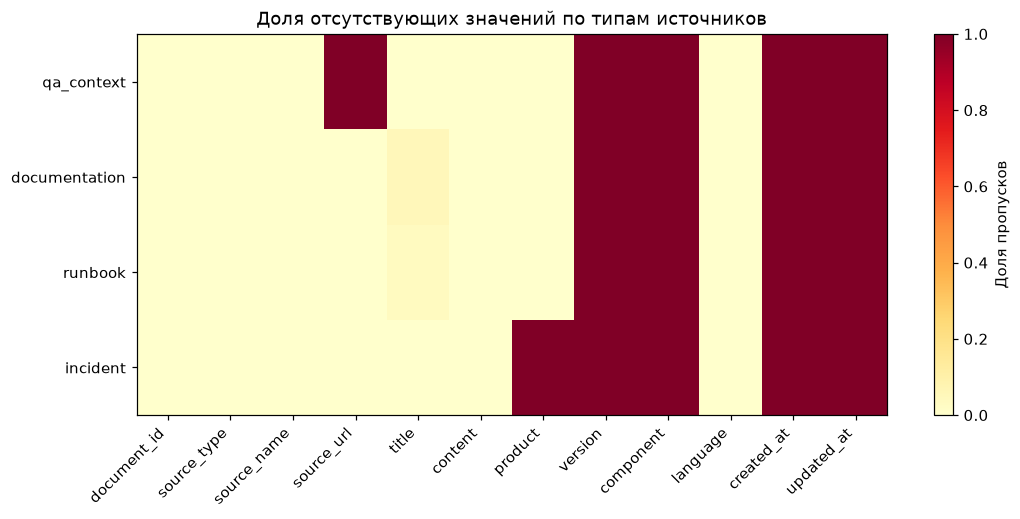

In [48]:
# Пересчёт пропусков на исходной унифицированной схеме
fields=['document_id','source_type','source_name','source_url','title','content','product','version','component','language','created_at','updated_at']
missing=pd.DataFrame({s: documents[documents.source_type==s][fields].isna().mean() for s in ORDER}).T
missing.index.name='source_type'
display(missing.T.sort_values('incident',ascending=False).round(3))
fig,ax=plt.subplots(figsize=(11,4.5))
im=ax.imshow(missing.values,aspect='auto',vmin=0,vmax=1,cmap='YlOrRd')
ax.set(xticks=range(len(fields)),yticks=range(len(ORDER)),xticklabels=fields,yticklabels=ORDER,title='Доля отсутствующих значений по типам источников')
plt.setp(ax.get_xticklabels(),rotation=45,ha='right');fig.colorbar(im,ax=ax,label='Доля пропусков');plt.show()

In [49]:
# Непосредственная проверка некачественных полей
empty_text=documents.content.fillna('').astype(str).str.strip().eq('')
empty_titles=documents.title.fillna('').astype(str).str.strip().eq('')
exact_content_dup=documents.content.fillna('').astype(str).str.strip().str.casefold().duplicated().sum()
quality=pd.DataFrame({
 'проверка':['Пустой основной текст','Пустой заголовок','Повтор ID документа','Повторы нормализованного текста','Битые QA→document ссылки'],
 'найдено':[int(empty_text.sum()),int(empty_titles.sum()),int(documents.document_id.duplicated().sum()),int(exact_content_dup),int(sum(not set(ids).issubset(set(documents.document_id)) for ids in qa.context_ids))]
})
display(quality)
near=pd.read_csv(ROOT/'reports/duplicate_pairs.csv')
print('Кандидаты на near-duplicate (из предварительного TF-IDF-поиска):',len(near))

,проверка,найдено
0,Пустой основной текст,0
1,Пустой заголовок,7
2,Повтор ID документа,0
3,Повторы нормализованного текста,0
4,Битые QA→document ссылки,0


Кандидаты на near-duplicate (из предварительного TF-IDF-поиска): 42


,класс,объектов,доля
0,Ответ существует,610,0.67
1,Нет ответа,300,0.33


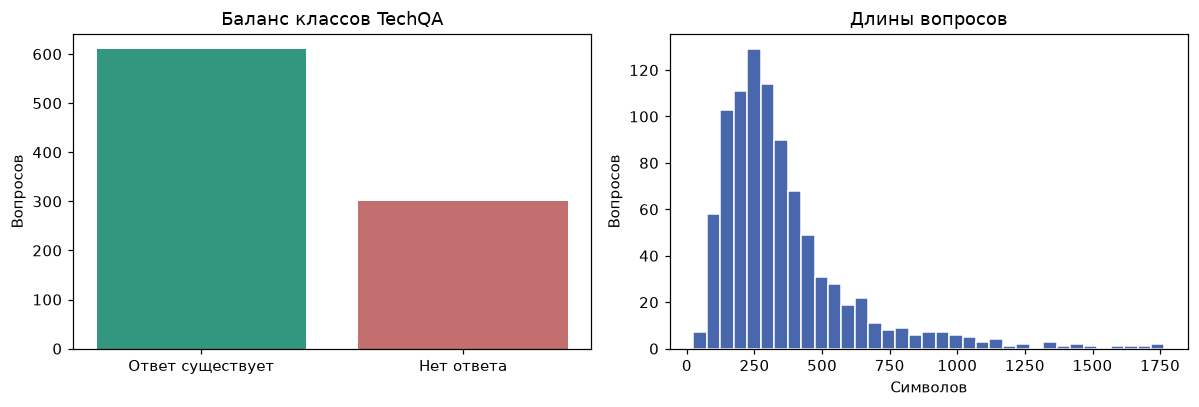

In [50]:
# QA — отдельная задача с бинарной меткой ответимости
qa['question_chars']=qa.question.fillna('').str.len()
qa['answer_chars']=qa.answer.fillna('').str.len()
qa['context_count']=qa.context_ids.apply(len)
answerability=qa.is_impossible.value_counts(dropna=False).rename({False:'Ответ существует',True:'Нет ответа'})
display(pd.DataFrame({'класс':answerability.index,'объектов':answerability.values,'доля':(answerability/len(qa)).round(3).values}))
fig,axs=plt.subplots(1,2,figsize=(11,3.8))
axs[0].bar(answerability.index,answerability.values,color=['#33967f','#c36f6f'])
axs[0].set(title='Баланс классов TechQA',ylabel='Вопросов')
axs[1].hist(qa.question_chars,bins=35,color=COLORS['qa_context'],edgecolor='white')
axs[1].set(title='Длины вопросов',xlabel='Символов',ylabel='Вопросов')
plt.tight_layout();plt.show()

In [51]:
# Проверяем реальную структуру splits и наследованные префиксы ID
splits=qa.groupby(['split','original_id_prefix'],dropna=False).agg(n=('query_id','size'),
              median_question_chars=('question_chars','median'),
              impossible_rate=('is_impossible','mean')).reset_index()
display(splits)
qnorm=qa.question.fillna('').str.lower().str.replace(r'\s+',' ',regex=True).str.strip()
qa['question_normalized']=qnorm
repeat_groups=qa.groupby('question_normalized').query_id.agg(list)
repeat_groups=repeat_groups[repeat_groups.map(len)>1]
print('Групп точных нормализованных дубликатов вопросов:',len(repeat_groups))
print('Повторяющихся записей сверх первого экземпляра:',int(sum(len(ids)-1 for ids in repeat_groups)))
# Показываем только ID, без больших фрагментов чужих вопросов
display(pd.DataFrame({'IDs':repeat_groups.head(8).map(lambda x:', '.join(x)).values}))

,split,original_id_prefix,n,median_question_chars,impossible_rate
0,train,DEV,310,296.0,0.483871
1,train,TRAIN,600,294.0,0.250000


Групп точных нормализованных дубликатов вопросов: 29
Повторяющихся записей сверх первого экземпляра: 29


,IDs
0,"DEV_Q298, TRAIN_Q138"
1,"TRAIN_Q358, TRAIN_Q398"
2,"DEV_Q300, TRAIN_Q228"
3,"DEV_Q165, TRAIN_Q160"
4,"DEV_Q082, TRAIN_Q238"
5,"DEV_Q156, TRAIN_Q047"
6,"DEV_Q129, TRAIN_Q206"
7,"DEV_Q180, TRAIN_Q559"


In [52]:
# Проверка возможных проблем меток и контекстов
missing_answer=qa.answer.fillna('').astype(str).str.strip().eq('')
missing_question=qa.question.fillna('').astype(str).str.strip().eq('')
answerable=~qa.is_impossible.astype(bool)
problems=pd.DataFrame({
'ситуация':['Пустой вопрос','Пустой ответ','Пустой ответ при answerable','Контекст при unanswerable','Нет контекста при answerable'],
'число':[int(missing_question.sum()),int(missing_answer.sum()),int((answerable & missing_answer).sum()),int(((~answerable)&(qa.context_count>0)).sum()),int((answerable & (qa.context_count==0)).sum())]
})
display(problems)
display(qa.groupby('is_impossible')[['question_chars','answer_chars','context_count']].agg(['median','mean']).round(1))

,ситуация,число
0,Пустой вопрос,0
1,Пустой ответ,2
2,Пустой ответ при answerable,2
3,Контекст при unanswerable,0
4,Нет контекста при answerable,0


question_chars        answer_chars        context_count     
                      median   mean       median   mean        median mean
is_impossible                                                             
False                  287.5  350.0        254.5  345.1           1.0  1.0
True                   313.5  373.4          1.0    1.0           0.0  0.0

**Вывод по QA.** Из 910 вопросов 610 помечены как имеющие ответ, а 300 — как неразрешимые по предоставленным данным. При этом у **двух вопросов из класса answerable поле ответа пустое**: эти записи нужно проверить и не включать в оценку генерации, пока разметка не исправлена. Найдено **29 групп одинаковых после нормализации вопросов**. Кроме того, все записи в подготовленном наборе имеют `split=train`, хотя ID сохраняют исходные префиксы `TRAIN` и `DEV`. Для следующего этапа необходимо восстановить корректное разделение и исключить пересечения вопросов и контекстов между выборками.

## 3. Чем отличаются четыре типа документов

Длину текста считаем в символах, словах и WordPiece-токенах. Для оценки работы embedding-модели используем сохранённые значения токенизации из `reports/document_features.csv`. Графики строим по каждому типу источника, чтобы большие группы не скрывали особенности маленьких.

In [53]:
# Пересчёт основных характеристик из текста и сравнение с подготовленными признаками
recomputed_chars=docs.content.fillna('').astype(str).str.len()
recomputed_words=docs.content.fillna('').astype(str).str.findall(r'\b\w+\b').str.len()
print('Совпадение числа символов с сохранённым feature:',round(float((recomputed_chars==docs.characters).mean()),4))
docs['char_count_inline']=recomputed_chars
docs['word_count_inline']=recomputed_words
summary=docs.groupby('source_type').agg(n=('document_id','size'),
    median_chars=('char_count_inline','median'),median_words=('word_count_inline','median'),
    median_wordpiece=('tokens','median'),p95_wordpiece=('tokens',lambda s:s.quantile(.95)),
    avg_code_share=('code_fraction','mean'),avg_tech_density=('technical_density','mean'))
display(summary.reindex(ORDER).round(2))

Совпадение числа символов с сохранённым feature: 1.0


,n,median_chars,median_words,median_wordpiece,p95_wordpiece,avg_code_share,avg_tech_density
source_type,,,,,,,
qa_context,496,2835.5,433.0,756.5,5099.50,0.00,0.22
documentation,95,5569.0,795.0,1569.0,8898.20,0.09,0.11
runbook,57,4929.0,680.0,1488.0,7880.20,0.09,0.20
incident,10,12463.0,1999.5,2854.5,7974.35,0.02,0.08


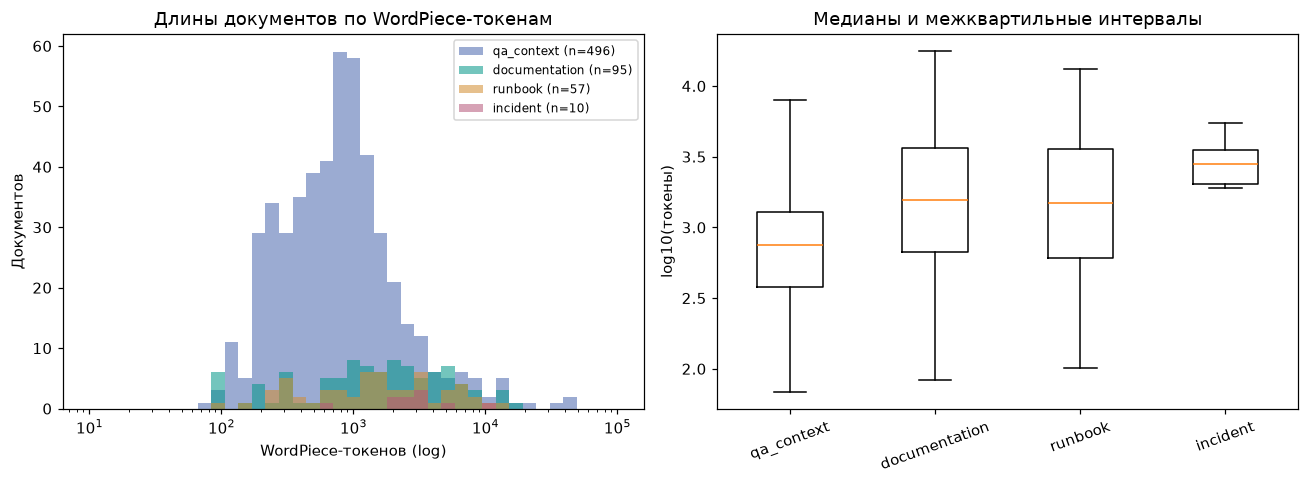

In [54]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for src in ORDER:
    a=docs[docs.source_type==src]
    axs[0].hist(a.tokens.clip(lower=1),bins=np.logspace(1,5,40),alpha=.55,label=f'{src} (n={len(a)})',color=COLORS[src])
axs[0].set_xscale('log');axs[0].set(title='Длины документов по WordPiece-токенам',xlabel='WordPiece-токенов (log)',ylabel='Документов')
axs[0].legend(fontsize=8)
axs[1].boxplot([np.log10(docs.loc[docs.source_type==s,'tokens'].clip(lower=1)) for s in ORDER],tick_labels=ORDER,showfliers=False)
axs[1].set(title='Медианы и межквартильные интервалы',ylabel='log10(токены)')
plt.setp(axs[1].get_xticklabels(),rotation=20);plt.tight_layout();plt.show()

,headings,code_fraction,links,commands,technical_density,timeline,root_cause,corrective_actions,symptoms,conditions
source_type,,,,,,,,,,
qa_context,0.107,0.000,9.228,0.016,0.223,0.099,0.665,0.224,0.492,0.750
documentation,8.495,0.094,5.853,5.684,0.114,0.105,0.474,0.105,0.379,0.863
runbook,12.018,0.092,10.930,3.105,0.204,0.175,0.456,0.175,0.579,0.807
incident,11.200,0.016,0.600,0.000,0.077,0.800,0.900,1.000,0.900,0.900


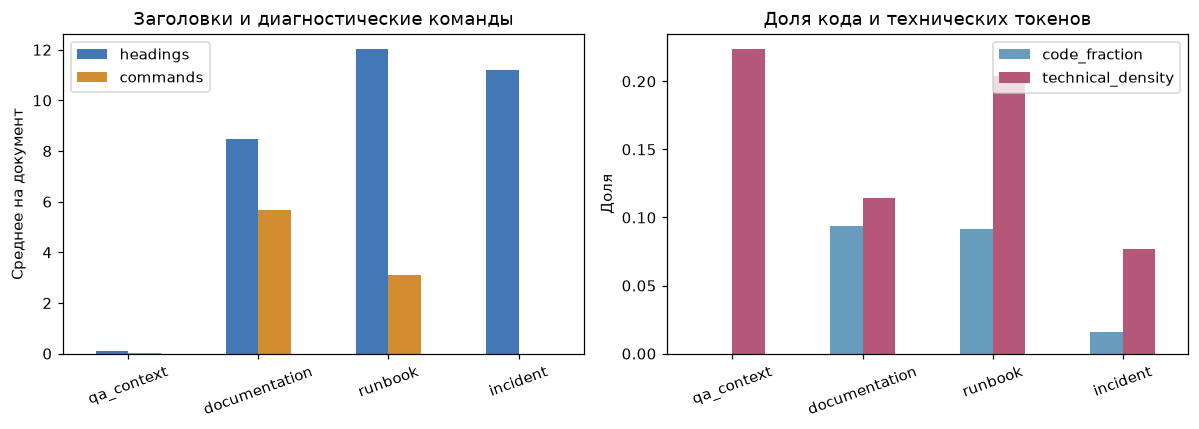

In [55]:
# Структурные признаки доступны для каждого источника; вычислены парсером исходных документов
structure_cols=['headings','code_fraction','links','commands','technical_density','timeline','root_cause','corrective_actions','symptoms','conditions']
struct=docs.groupby('source_type')[structure_cols].mean().reindex(ORDER)
display(struct.round(3))
fig,axs=plt.subplots(1,2,figsize=(11,4))
struct[['headings','commands']].plot(kind='bar',ax=axs[0],color=['#4378b7','#d28d30'])
axs[0].set(title='Заголовки и диагностические команды',ylabel='Среднее на документ',xlabel='');axs[0].tick_params(axis='x',rotation=20)
struct[['code_fraction','technical_density']].plot(kind='bar',ax=axs[1],color=['#689cbd','#b55779'])
axs[1].set(title='Доля кода и технических токенов',ylabel='Доля',xlabel='');axs[1].tick_params(axis='x',rotation=20)
plt.tight_layout();plt.show()

### 3.1. Техническая документация

В выборке 95 документов Kubernetes. Их медианная длина — **1 569 WordPiece-токенов**, а в наиболее длинных документах встречаются десятки разделов. При построении RAG-индекса стоит сохранять заголовки вместе с относящимися к ним командами и конфигурацией. Ниже показаны самые длинные документы и особенности их разметки.

In [56]:
doc_only=docs[docs.source_type=='documentation']
display(doc_only[['document_id','title','tokens','headings','code_fraction','links']].sort_values('tokens',ascending=False).head(8).round(3))
print('Документов с разметкой заголовков:',int((doc_only.headings>0).sum()),'из',len(doc_only))
print('Медиана WordPiece-токенов:',int(doc_only.tokens.median()))

,document_id,title,tokens,headings,code_fraction,links
45,documentation_7b90e77b28248a6dd33b,ClusterRole,17629,50,0.000,17
41,documentation_70b35b750a602b2e989d,Volumes,14666,52,0.109,24
12,documentation_2598b278c769d8cf78c0,kube-proxy Configuration (v1alpha1),13659,23,0.000,22
87,documentation_e988cf385a2e9bc91733,Diagram Guide,13177,14,0.059,50
17,documentation_2bd0b1d26dbcdf34cae6,Configure a Security Context for a Pod or Cont...,9146,19,0.108,28
11,documentation_23b5ad9815a2c4d17fd5,Horizontal Pod Autoscaling,8792,26,0.040,5
37,documentation_61009b04d96912bb583e,Updating Configuration via a ConfigMap,7902,28,0.412,12
34,documentation_54c2092d43a54b795d51,Debug Services,7243,18,0.359,4


Документов с разметкой заголовков: 83 из 95
Медиана WordPiece-токенов: 1569


### 3.2. Runbooks

Runbook — инструкция для конкретной ситуации, например сбоя сервиса или проблемы с базой данных. Среди 57 документов GitLab текстовые признаки условий встречаются в **80,7%**, а ожидаемого результата — в **52,6%**. Мы нашли их автоматически по характерным формулировкам.

При разбиении runbook важно сохранять вместе условие, команду и проверку результата. Иначе поисковик может вернуть команду без объяснения, когда её применять.

In [57]:
runbooks=docs[docs.source_type=='runbook']
runbook_view=runbooks[['document_id','title','tokens','commands','conditions','expected_result','code_fraction']]
display(runbook_view.sort_values('commands',ascending=False).head(8).round(2))
print('Наличие словесных маркеров условий:',f'{runbooks.conditions.mean():.1%}')
print('Наличие маркеров ожидаемого результата:',f'{runbooks.expected_result.mean():.1%}')

,document_id,title,tokens,commands,conditions,expected_result,code_fraction
636,runbook_8531ffd0ef12aed7c7e8,Credential rotation,4884,33,True,True,0.43
645,runbook_c677a5bedaa63f503a49,PostgreSQL Backups: WAL-G,10266,27,True,True,0.21
635,runbook_8360ec62ddde97cef205,Postgresql minor upgrade,824,21,True,True,0.20
619,runbook_3d9dcba934e7efe8fba5,WAL receiver: restore with the receiver's files,1618,12,True,True,0.21
641,runbook_a0626e9fbc966cd49741,WalReceiverNotConnected,1714,10,True,True,0.12
647,runbook_c95bad92316ab4a06585,KubeSchedulingFailures,7722,8,True,True,0.08
643,runbook_b844286ba626cb649434,Redis-Sidekiq catchall workloads reduction,578,7,True,True,0.00
642,runbook_b56aca631463f67c5355,Kubernetes runner managers,6923,7,True,True,0.02


Наличие словесных маркеров условий: 80.7%
Наличие маркеров ожидаемого результата: 52.6%


### 3.3. Отчёты об инцидентах

Мы собрали **10 отчётов** разных компаний. Медианная длина — **2 854,5 WordPiece-токена**. Для каждого проверяем, как описаны симптомы, ход событий, причины и последующие действия.

Один отчёт написан на корейском. В эксперимент с англоязычной MiniLM вошли остальные девять.

,document_id,title,tokens,timeline,root_cause,corrective_actions,symptoms
95,incident_2f94ea598c99e5b8cbf1,DNS Outage Post Mortem - The GitHub Blog,1950,True,True,True,True
96,incident_5d130ce893fec0c2f4b2,"1.1.1.1 lookup failures on October 4, 2023 | ...",3345,True,True,True,True
97,incident_67178eb044eea14d20ce,"Summary of the Amazon EC2, Amazon EBS, and Ama...",9998,True,True,True,True
98,incident_6ecf86458221638c5bcd,Slack’s Outage on January 4th 2021 | Engineer...,2364,True,True,True,True
99,incident_a54d7767497a3db664c7,GitHub Availability Report: August 2024 - The ...,592,True,False,True,True
100,incident_b6719e72e0f221e0e358,"Cloudflare incident on January 24, 2023 | Clou...",3382,True,True,True,True
101,incident_bc840ee604ab31fea70e,GitLab.com database incident,1889,True,True,True,True
102,incident_bce133b93828728db90d,아시아-태평양 서울 리전(AP-NorthEast-2)의 Amazon EC2 DNS ...,2331,False,True,True,False
103,incident_f8356210c986a6009b43,Slack’s Incident on 2-22-22 | Engineering at ...,3604,False,True,True,True
104,incident_f962a1878a6cd9e9b1a0,Postmortem of database outage of January 31,5501,True,True,True,True


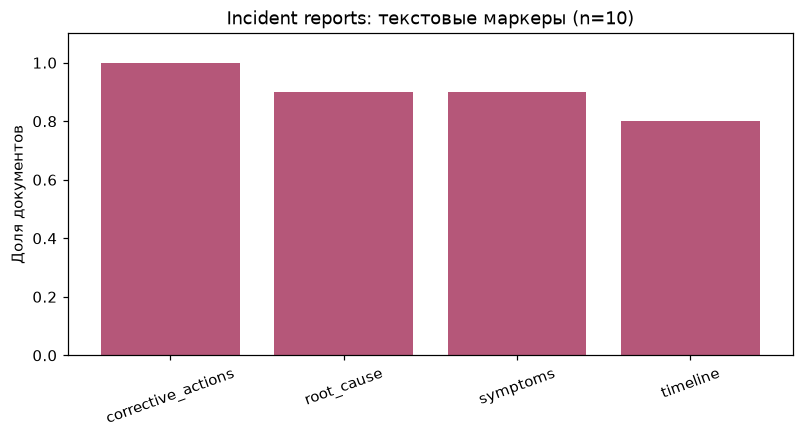

In [58]:
inc=docs[docs.source_type=='incident']
display(inc[['document_id','title','tokens','timeline','root_cause','corrective_actions','symptoms']].round(2))
fig,ax=plt.subplots(figsize=(8.5,3.8))
markers=['timeline','root_cause','corrective_actions','symptoms']
mark_rates=inc[markers].mean().sort_values(ascending=False)
ax.bar(mark_rates.index,mark_rates.values,color='#b55779')
ax.set(title=f'Incident reports: текстовые маркеры (n={len(inc)})',ylabel='Доля документов',ylim=(0,1.1))
plt.setp(ax.get_xticklabels(),rotation=20);plt.show()

**Вывод по структуре.** Медианная длина QA-контекста — **756,5 токена**, документа Kubernetes — **1 569**, runbook — **1 488**, отчёта об инциденте — **2 854,5**. Из-за таких различий единый размер чанка может работать неодинаково. Следующий шаг — сравнить обычное разбиение по длине со структурным: для документации сохранять разделы, для runbooks — последовательность действий, для инцидентов — связь симптомов и причин.

## 4. Сравнение источников: словари и технические маркеры

Один и тот же сбой может быть описан по-разному: пользователь пишет про ошибку, документация — про настройку, runbook — про команду проверки. Сначала посмотрим, насколько пересекается словарь источников, затем сравним их эмбеддинги.

Словари (первые 10 000 токенов на источник): {'qa_context': 1711, 'documentation': 2202, 'runbook': 2546, 'incident': 1667}


,qa_context,documentation,runbook,incident
qa_context,1.000,0.150,0.128,0.135
documentation,0.150,1.000,0.166,0.158
runbook,0.128,0.166,1.000,0.164
incident,0.135,0.158,0.164,1.000


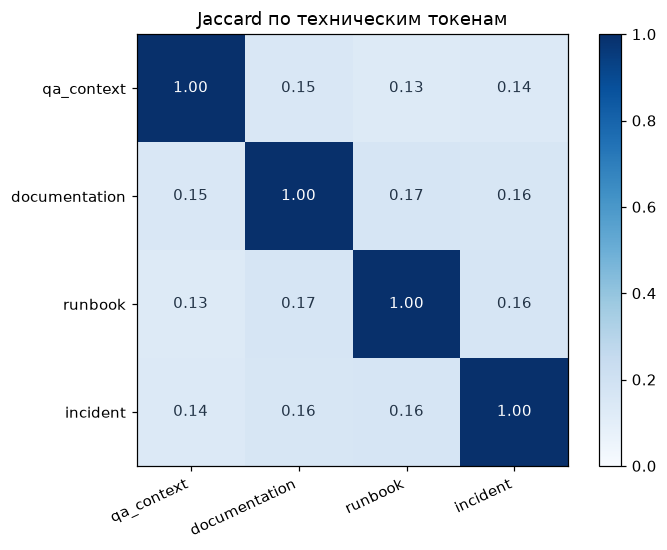

In [59]:
# Пересчитываем source-level Jaccard из реального текста; фиксируем бюджет для сопоставимости.
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

word_re=re.compile(r"[A-Za-z][A-Za-z0-9_.:/-]{2,}")
vocabulary={}
for src in ORDER:
    corpus=' '.join(docs.loc[docs.source_type==src,'content'].astype(str).tolist())
    tokens=[t.lower() for t in word_re.findall(corpus)][:10000]
    vocabulary[src]={t for t in tokens if t not in ENGLISH_STOP_WORDS}
overlap=pd.DataFrame(index=ORDER,columns=ORDER,dtype=float)
for a in ORDER:
    for b in ORDER:
        intersection=len(vocabulary[a]&vocabulary[b]);union=len(vocabulary[a]|vocabulary[b])
        overlap.loc[a,b]=intersection/union if union else np.nan
print('Словари (первые 10 000 токенов на источник):', {s:len(vocabulary[s]) for s in ORDER})
display(overlap.round(3))
fig,ax=plt.subplots(figsize=(6.8,5.1))
im=ax.imshow(overlap.values,cmap='Blues',vmin=0,vmax=1)
ax.set(xticks=range(4),yticks=range(4),xticklabels=ORDER,yticklabels=ORDER,title='Jaccard по техническим токенам')
plt.setp(ax.get_xticklabels(),rotation=25,ha='right')
for (i,j),v in np.ndenumerate(overlap.values): ax.text(j,i,f'{v:.2f}',ha='center',va='center',color='white' if v>.55 else '#233447')
fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()

,HTTP status (%),Версии x.y.z (%),Пути файлов (%),CLI-префиксы (%)
source_type,,,,
qa_context,3.6,52.6,76.4,1.0
documentation,3.2,17.9,90.5,62.1
runbook,7.0,8.8,91.2,47.4
incident,0.0,30.0,30.0,20.0


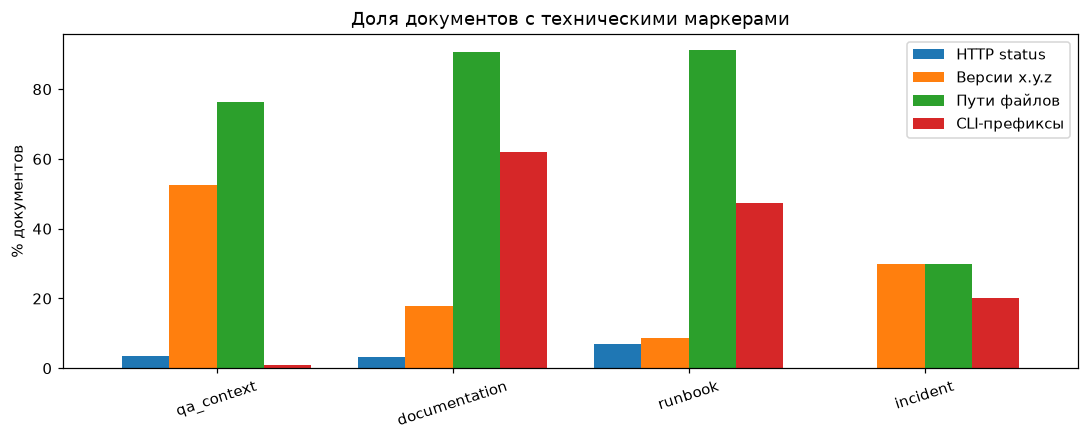

In [60]:
# Проверяем распространённость кодов ошибок, версий и путей, не удаляя технические символы.
markers={
    'HTTP status':r'\b(?:400|401|403|404|429|500|502|503|504)\b',
    'Версии x.y.z':r'\b\d+\.\d+\.\d+(?:[.-]\w+)?\b',
    'Пути файлов':r'(?<!\w)/(?:[A-Za-z0-9_.-]+/){1,}[A-Za-z0-9_.-]+',
    'CLI-префиксы':r'\b(?:kubectl|psql|git|sudo|curl|docker)\b'
}
marker_data={key:docs.content.fillna('').str.contains(pattern,flags=re.I,regex=True).groupby(docs.source_type).mean().reindex(ORDER) for key,pattern in markers.items()}
marker_share=pd.DataFrame(marker_data)
display((marker_share*100).round(1).add_suffix(' (%)'))
ax=(marker_share*100).plot(kind='bar',figsize=(10,4.1),width=.8)
ax.set(title='Доля документов с техническими маркерами',ylabel='% документов',xlabel='')
plt.xticks(rotation=18);plt.tight_layout();plt.show()

**Вывод по лексике.** Пересечение словарей TechQA и Kubernetes — **0,150**, Kubernetes и runbooks — **0,166** (при одинаковом ограничении до 10 тысяч токенов). Источники используют заметно разную лексику: запрос поддержки, техническая справка и рабочая инструкция часто описывают одну тему разными словами.

Для поиска это важный сигнал: сохраним коды ошибок, команды и версии ПО, а затем сравним BM25, dense search и их комбинацию.

## 5. Эмбеддинги MiniLM и PCA

Для семантического анализа используем `sentence-transformers/all-MiniLM-L6-v2`. Длинные документы разбили на пересекающиеся окна WordPiece, рассчитали эмбеддинги и объединили их в один вектор для каждого документа.

В эксперимент вошёл **221 документ**: 95 документов Kubernetes, 60 контекстов TechQA, 57 runbooks и 9 англоязычных отчётов об инцидентах. Ниже смотрим на расположение текстов в PCA и на значения cosine similarity.

In [61]:
emb=np.load(ROOT/'data/processed/document_embeddings.npy')
emb_ids=json.loads((ROOT/'data/processed/embedding_document_ids.json').read_text(encoding='utf-8'))
assert emb.shape[0]==len(emb_ids) and emb.shape[1]==384
emb_meta=docs.set_index('document_id').loc[emb_ids][['source_type','source_name','title']].reset_index()
coords=PCA(n_components=2,random_state=SEED).fit_transform(emb)
emb_meta['PC1'],emb_meta['PC2']=coords[:,0],coords[:,1]
print('Фактическая матрица эмбеддингов:',emb.shape)
display(emb_meta.source_type.value_counts().rename('объектов').to_frame())

Фактическая матрица эмбеддингов: (221, 384)


,объектов
source_type,
documentation,95
qa_context,60
runbook,57
incident,9


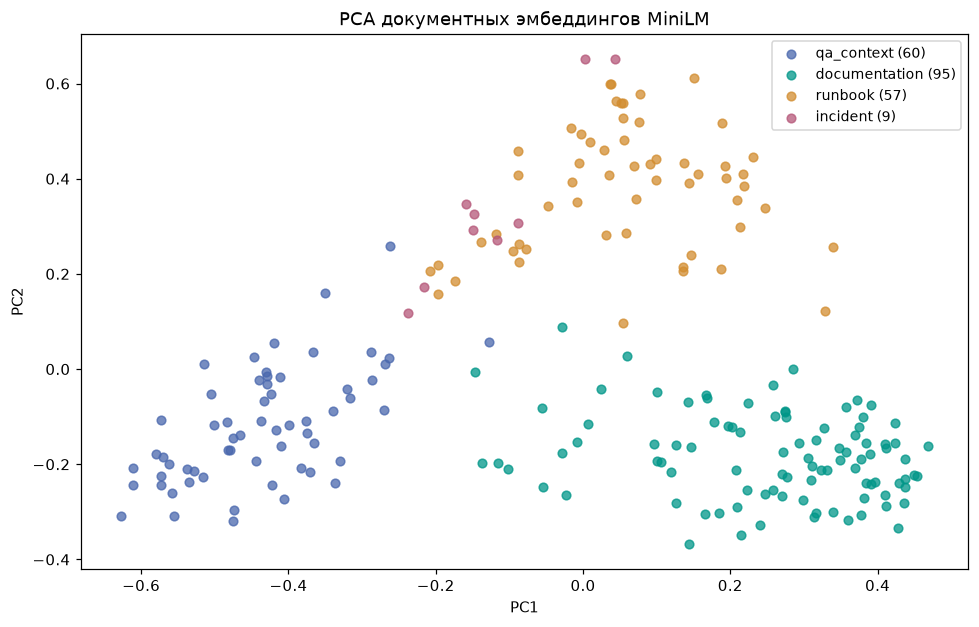

In [62]:
fig,ax=plt.subplots(figsize=(9,5.8))
for src in ORDER:
    t=emb_meta[emb_meta.source_type==src]
    ax.scatter(t.PC1,t.PC2,s=32,alpha=.75,label=f'{src} ({len(t)})',color=COLORS[src])
ax.set(title='PCA документных эмбеддингов MiniLM',xlabel='PC1',ylabel='PC2');ax.legend(fontsize=9)
plt.tight_layout();plt.show()

In [63]:
# Прямые попарные cosine similarity без скрытого вызова pipeline.
cs=cosine_similarity(emb)
sampled=[]
for i,a in enumerate(ORDER):
    for b in ORDER[i:]:
        ia=np.flatnonzero(emb_meta.source_type.to_numpy()==a)
        ib=np.flatnonzero(emb_meta.source_type.to_numpy()==b)
        if a==b:
            pairs=np.array(np.triu_indices(len(ia),k=1)).T
            values=cs[ia[pairs[:,0]],ia[pairs[:,1]]] if len(pairs) else np.array([])
        else:
            values=cs[np.ix_(ia,ib)].ravel()
        if len(values)>500: values=rng.choice(values,size=500,replace=False)
        if len(values): sampled.append({'Пара':f'{a} / {b}','N':len(values),'mean_cosine':float(np.mean(values)),'median_cosine':float(np.median(values))})
sim_table=pd.DataFrame(sampled).sort_values('median_cosine',ascending=False)
display(sim_table.round(3))

,Пара,N,mean_cosine,median_cosine
9,incident / incident,36,0.511,0.503
7,runbook / runbook,500,0.445,0.452
4,documentation / documentation,500,0.427,0.419
0,qa_context / qa_context,500,0.367,0.353
8,runbook / incident,500,0.335,0.326
5,documentation / runbook,500,0.268,0.257
3,qa_context / incident,500,0.188,0.183
6,documentation / incident,500,0.167,0.166
1,qa_context / documentation,500,0.161,0.163
2,qa_context / runbook,500,0.157,0.147


**Вывод по эмбеддингам.** Медианное cosine similarity между документацией Kubernetes и runbooks GitLab — **0,257**; внутри документации — **0,419**, внутри runbooks — **0,452**. То есть MiniLM заметно чаще сближает тексты одного источника.

Это объясняет, зачем нам отдельный эксперимент по multi-source retrieval: нужно проверить, не теряет ли единый поиск хорошие инструкции и инциденты среди большого количества документов.

## 6. Поиск материалов для диагностических сценариев

Составили **10 диагностических сценариев** и нашли для них **90 документов-кандидатов** из документации, runbooks и отчётов об инцидентах. Сравниваем, что предлагают BM25 и dense search. После этого вручную оценим, какие из найденных материалов действительно помогают разобраться в проблеме.

Запросов: 10 кандидатов: 90
Проверенных вручную: 0 из 90


,candidates,mean_candidate_cosine
source_type,,
documentation,30,0.316
incident,30,0.367
runbook,30,0.403


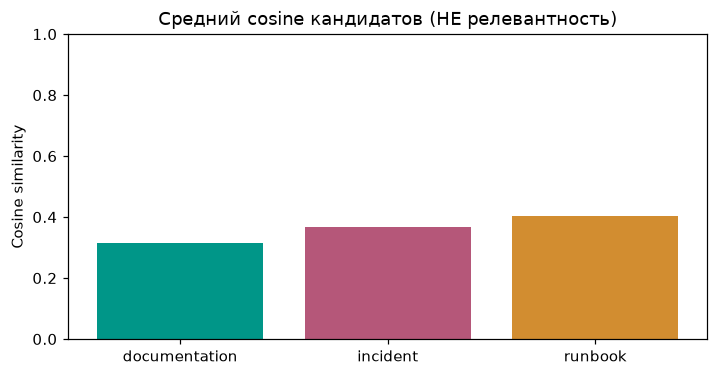

In [64]:
coverage=pd.read_csv(ROOT/'reports/coverage_review.csv',keep_default_na=False)
# Показываем метаданные и рейтинги, но не публикуем объёмные цитаты сторонних авторов.
labels=coverage.human_label.astype(str).str.strip()
print('Запросов:',coverage.query_id.nunique(),'кандидатов:',len(coverage))
print('Проверенных вручную:',int(labels.isin(['0','1','2']).sum()),'из',len(coverage))
by_src=coverage.groupby('source_type').agg(candidates=('document_id','size'),mean_candidate_cosine=('cosine','mean'))
display(by_src.round(3))
fig,ax=plt.subplots(figsize=(7.5,3.6))
ax.bar(by_src.index,by_src.mean_candidate_cosine,color=[COLORS[s] for s in by_src.index])
ax.set(title='Средний cosine кандидатов (НЕ релевантность)',ylabel='Cosine similarity',ylim=(0,1))
plt.show()

Сравниваемые методы: Dense vs BM25; строк: 30


,n,mean_overlap_at3,median_overlap_at3
source_type,,,
documentation,10,0.267,0.333
incident,10,0.600,0.667
runbook,10,0.300,0.333


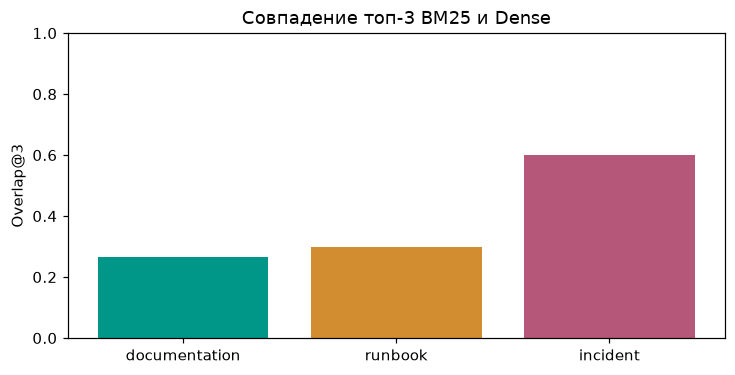

In [65]:
retr=pd.read_csv(ROOT/'reports/retrieval_candidates.csv')
print('Сравниваемые методы: Dense vs BM25; строк:',len(retr))
display(retr.groupby('source_type').agg(n=('query_id','size'),mean_overlap_at3=('overlap_at3','mean'),median_overlap_at3=('overlap_at3','median')).round(3))
fig,ax=plt.subplots(figsize=(7.7,3.6))
means=retr.groupby('source_type').overlap_at3.mean().reindex(['documentation','runbook','incident'])
ax.bar(means.index,means.values,color=[COLORS[s] for s in means.index]);ax.set(ylim=(0,1),title='Совпадение топ-3 BM25 и Dense',ylabel='Overlap@3')
plt.show()

**Вывод по поиску.** Среднее совпадение топ-3 BM25 и dense search — **0,267** для документации, **0,300** для runbooks и **0,600** для инцидентов. Методы часто возвращают разные документы.

Это хороший повод протестировать hybrid retrieval. Но сначала разметим, какие ответы полезны: пока у нас есть только выдача, а не оценка её качества. После разметки посчитаем Recall@K, MRR и nDCG.

## 7. Аугментации технических вопросов

Проверяем два способа: перефразирование и опечатки в обычных словах. Для каждого подготовлено по **20 запросов**. Номера версий, коды ошибок и технические параметры не меняем: их изменение может сделать исходный ответ неправильным.

,n,mean_cosine,median_cosine,mean_length_delta,entity_preservation_rate
method,,,,,
paraphrase,20,0.941,0.946,-89.4,1.0
typo,20,0.969,0.980,0.0,1.0


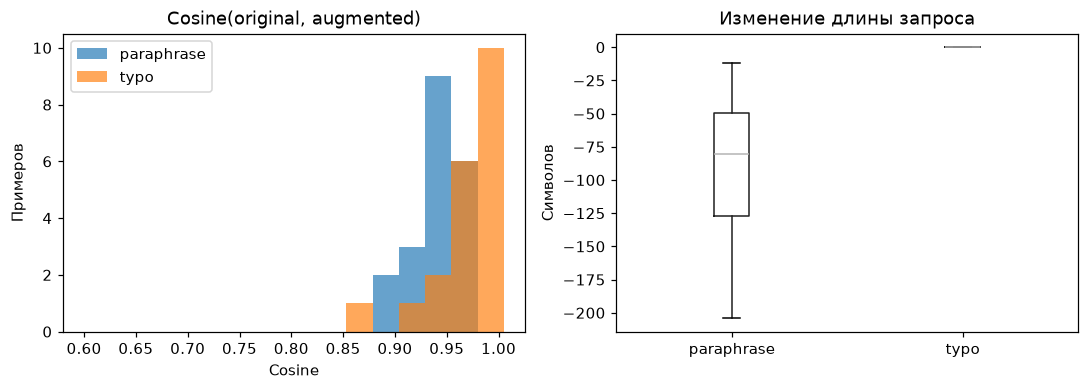

In [66]:
aug=pd.read_csv(ROOT/'reports/augmentations.csv',keep_default_na=False)
aug['cosine']=pd.to_numeric(aug.cosine,errors='coerce')
aug['length_delta']=pd.to_numeric(aug.length_delta,errors='coerce')
aug['entity_preserved']=aug.entity_subset_preserved.astype(str).str.lower().map({'true':True,'false':False})
aug_stat=aug.groupby('method').agg(n=('original_id','size'),mean_cosine=('cosine','mean'),
        median_cosine=('cosine','median'),mean_length_delta=('length_delta','mean'),
        entity_preservation_rate=('entity_preserved','mean')).round(3)
display(aug_stat)
fig,axs=plt.subplots(1,2,figsize=(10,3.8))
for method,part in aug.groupby('method'):
    axs[0].hist(part.cosine,bins=np.linspace(.6,1.005,17),alpha=.68,label=method)
axs[0].set(title='Cosine(original, augmented)',xlabel='Cosine',ylabel='Примеров');axs[0].legend()
aug.boxplot(column='length_delta',by='method',ax=axs[1],grid=False)
axs[1].set(title='Изменение длины запроса',xlabel='',ylabel='Символов')
fig.suptitle('');plt.tight_layout();plt.show()

In [67]:
# Контрольные пары идентифицируем по query ID; длинные тексты не выводим целиком.
display(aug[['original_id','method','cosine','length_delta','entity_subset_preserved','semantic_review']].head(12))
print('Записей с однозначной ручной разметкой смысла:',int(aug.semantic_review.astype(str).str.strip().isin(['pass','fail','valid','invalid']).sum()))

,original_id,method,cosine,length_delta,entity_subset_preserved,semantic_review
0,TRAIN_Q001,paraphrase,0.884719,-80,True,agent draft; human unreviewed
1,TRAIN_Q001,typo,0.980577,0,True,agent draft; human unreviewed
2,TRAIN_Q003,paraphrase,0.954362,-133,True,agent draft; human unreviewed
3,TRAIN_Q003,typo,0.988458,0,True,agent draft; human unreviewed
4,TRAIN_Q005,paraphrase,0.958170,-38,True,agent draft; human unreviewed
5,TRAIN_Q005,typo,0.980501,0,True,agent draft; human unreviewed
6,TRAIN_Q006,paraphrase,0.957353,-101,True,agent draft; human unreviewed
7,TRAIN_Q006,typo,0.988784,0,True,agent draft; human unreviewed
8,TRAIN_Q008,paraphrase,0.976306,-52,True,agent draft; human unreviewed
9,TRAIN_Q008,typo,0.992869,0,True,agent draft; human unreviewed


Записей с однозначной ручной разметкой смысла: 0


**Вывод по аугментациям.** Средняя близость к исходному вопросу — **0,941** для перефразирований и **0,969** для опечаток. Во всех 40 вариантах сохранились технические идентификаторы, которые распознают наши регулярные выражения.

Теперь нужно вручную просмотреть примеры: главное, чтобы новая формулировка не изменила саму проблему. Затем сравним результаты поиска на исходных и изменённых вопросах.

## 8. Что показал EDA и как это влияет на проект

| Наблюдение | Решение для Incident Copilot | Что проверить дальше |
|---|---|---|
| Длины документов отличаются в несколько раз | Сравнить обычный и структурный chunking | Recall@K для обоих способов разбиения |
| В данных много команд, версий и идентификаторов | Сохранять технические символы, добавить BM25 к dense search | BM25, dense и hybrid на одном тесте |
| 29 групп повторяющихся QA-вопросов и 2 пустых ответа | Очистить QA-разметку, разделить данные по связанным вопросам и контекстам | Проверить пересечения train/test |
| В runbooks важен порядок действий | Не отделять команду от условий и проверки результата | Ручная оценка найденных инструкций |
| Только 10 отчётов об инцидентах | Расширить корпус и группировать отчёты по событиям | Анализ новых инцидентов и дубликатов |
| TechQA и инфраструктурные документы относятся к разным продуктам | Оставить TechQA отдельным QA-бенчмарком, создать согласованный SRE-корпус | Поиск внутри одного продукта и между источниками |
| BM25 и dense находят разные документы | Создать небольшую разметку релевантности | Recall@K, MRR и nDCG |
| Аугментации меняют представление вопроса | Добавлять в обучение только проверенные варианты | Проверка смысла и устойчивости retrieval |


### Как воспроизвести анализ

Основные данные и вычисленные признаки хранятся в локальном снимке, описанном в `data/README.md`. Код загрузки и подготовки данных — в `src/eda/`. После подготовки корпуса ноутбук запускается целиком из корня репозитория; сохраняются рассчитанные таблицы и графики.

In [68]:
# Финальная воспроизводимая проверка фактических результатов
assert len(documents)==658 and len(qa)==910
assert documents.document_id.is_unique and qa.query_id.is_unique
assert not documents.content.fillna('').astype(str).str.strip().eq('').any()
assert len(emb_ids)==len(emb) and set(emb_ids).issubset(set(docs.document_id))
print('EDA: PASSED — схема, связи QA, документные векторы и ключевые объёмы проверены')

EDA: PASSED — схема, связи QA, документные векторы и ключевые объёмы проверены
